In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MaxAbsScaler, FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.model_selection import cross_validate, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.neural_network import MLPRegressor
from scipy import stats
from scipy.stats import mannwhitneyu
from scipy.stats import f_oneway, kruskal

In [3]:
url_gasto_energetico = "../data/processed/datos_limpios.csv"

df_gasto_energetico = pd.read_csv(url_gasto_energetico)

print(df_gasto_energetico.info())


<class 'pandas.DataFrame'>
RangeIndex: 19544 entries, 0 to 19543
Data columns (total 87 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   GASTO_SUMINISTROS  19544 non-null  float64
 1   CCAA               19544 non-null  str    
 2   NUTS1              19544 non-null  str    
 3   CAPROV             19544 non-null  str    
 4   TAMAMU             19544 non-null  str    
 5   DENSIDAD           19544 non-null  str    
 6   NMIEMB             19544 non-null  int64  
 7   NMIEM1             19544 non-null  int64  
 8   NMIEM2             19544 non-null  int64  
 9   NMIEM3             19544 non-null  int64  
 10  NMIEM4             19544 non-null  int64  
 11  NMIEM5             19544 non-null  int64  
 12  NMIEM6             19544 non-null  int64  
 13  NMIEM7             19544 non-null  int64  
 14  NMIEM8             19544 non-null  int64  
 15  NMIEM9             19544 non-null  int64  
 16  NMIEM10            19544 non-null

In [4]:
train_set, test_set = train_test_split(df_gasto_energetico, test_size=0.2, random_state=42)
target = "GASTO_SUMINISTROS"

X_train = train_set.drop(columns=[target]).copy()
y_train = train_set[target].copy()

X_test = test_set.drop(columns=[target]).copy()
y_test = test_set[target].copy()

In [11]:
no_num = df_gasto_energetico.select_dtypes(exclude="number").columns.tolist()

no_num_binary = [
    col for col in no_num
    if df_gasto_energetico[col].nunique(dropna=False) == 2
]

bin_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(
        min_frequency=0.01,   # agrupa categorías con menos del 1 % de frecuencia
        max_categories=15,    # tope de 15 columnas (incluyendo la de "raras")
        handle_unknown="infrequent_if_exist",
        sparse_output=False,
    )),
])

X_train_bin = bin_pipeline.fit_transform(df_gasto_energetico[no_num_binary])

cols_bin_out = bin_pipeline.get_feature_names_out(no_num_binary)
df_train_bin = pd.DataFrame(X_train_bin, columns=cols_bin_out, index=df_gasto_energetico.index)

no_num_multi =  [col for col in no_num if col not in no_num_binary]

In [13]:
# no_num = df_gasto_energetico.select_dtypes(exclude="number").columns.tolist()

# no_num_binary = [
#     col for col in no_num
#     if df_gasto_energetico[col].nunique(dropna=False) == 2
# ]

# no_num_multi =  [col for col in no_num if col not in no_num_binary]

In [6]:
cols_excluidas = [
    # Hogar: redundantes con NMIEMB y TIPHOGAR1 (|r| > 0.8-0.99 entre ellas)
    "NMIEM1", "NMIEM2", "NMIEM3", "NMIEM4", "NMIEM5", "NMIEM6", "NMIEM7", "NMIEM8", "NMIEM9", "NMIEM10", "NMIEM11", "NMIEM12", "NMIEM13",
    "PF2TEO", "PF2RECO", "UC1", "UC2", "NUMACTI", "NUMINACTI", "NUMOCUP", "NUMNOCUP", "NUMESTU", "NUMNOESTU", "NNINOSD", "NHIJOSD", "NUMPERI",
    # Versiones derivadas o redundantes de otra variable que ya se mantiene
    "NUTS1", "TIPHOGAR7", "TIPHOGAR8", "SITSOCI", "OCUPA", "OCUPARED", "FUENPRIN", "SITUACTSP", "SITUREDSP",
    "ACTESTB", "ACTESTBRED", "CALEF", "AGUACALI", "OCUSP", "SITPROF", "TIPOCONT",
    # Señal casi nula (eta² < 0.005, |ρ| < 0.05 o p > 0.05)
    "ESTUDIOSSP", "ESTUDREDSP", "JORNADASP", "CONTRATO", "PERCEPSP", "SECTOR", "PAISNACSP", "PAISPADRESP", "PAISMADRESP", "NACIONASP",
    "SITURESSP", "PENSIOINCAP", "OTROIN", "DESEM", "PENSIOTR", "RENTAS", "PENSIOJUB", "ANNOCON", "DISPOSIOV", "TRABAJO",
]

In [7]:
grupos_cat = {
    "grupo_a_suministros_estructural": ["FUENCALE", "FUENAGUA"],
    "grupo_b_empleo_estatus_multiclase": [
        "OCUPA", "OCUPARED", "ACTESTB", "ACTESTBRED",
        "SITPROF", "SITSOCI", "SITSOCIRE"
    ],
    "grupo_c_ingresos_principales": ["FUENPRIN", "FUENPRINRED"],
    "grupo_d_territorio": ["CCAA", "NUTS1", "CAPROV", "TAMAMU", "DENSIDAD", "ZONARES"],
    "grupo_e_tipologia_hogar": ["TIPHOGAR1", "TIPHOGAR7", "TIPHOGAR8"],
    "grupo_f_demografia_sp": [
        "SEXOSP", "PAISNACSP", "NACIONASP", "ESTADOCIVILSP",
        "PAISPADRESP", "PAISMADRESP", "ESTUDIOSSP",
        "ESTUDREDSP", "SITUACTSP", "SITUREDSP", "PERCEPSP"
    ],
    "grupo_g_vivienda_cat": [
        "REGTEN", "TIPOEDIF", "TIPOCASA", "ANNOCON", "AGUACALI", "DISPOSIOV"
    ],
    "grupo_h_binarias_laborales_estructurales": [
        "JORNADASP", "SECTOR", "CONTRATO", "TIPOCONT", "TRABAJO"
    ],
    "grupo_i_ingresos_y_tenencia_bin": [
        "CAPROP", "CAJENA", "PENSIOTR", "DESEM", "OTRSUB", "RENTAS", "PENSIOJUB"
    ],
}

In [8]:
cat_multiclase_cols = no_num_multi

In [9]:
no_aplica_cols = (
    grupos_cat["grupo_a_suministros_estructural"]
    + grupos_cat["grupo_h_binarias_laborales_estructurales"]
)
no_consta_cols = grupos_cat["grupo_b_empleo_estatus_multiclase"]
moda_cat_cols = (
    grupos_cat["grupo_c_ingresos_principales"]
    + grupos_cat["grupo_d_territorio"]
    + grupos_cat["grupo_e_tipologia_hogar"]
    + grupos_cat["grupo_f_demografia_sp"]
    + grupos_cat["grupo_g_vivienda_cat"]
    + grupos_cat["grupo_i_ingresos_y_tenencia_bin"]
)

# Ajusta estas dos listas a tus columnas numéricas finales (sin la target ni excluidas)
num_con_nulos = ["VALOREST", "NHABIT"]

num_sin_nulos = [
    "NMIEMB", "NMIEM4", "NMIEM9", "NMIEM10",
    "NUMOCUP", "NUMNOCUP", "NNINOSD",
    "UC1", "UC2", "PF2TEO", "PF2RECO",
    "EDADSP", "SUPERF", "IMPEXAC", "NUMPERI",
]

no_aplica_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="No_aplica")),
    ("ohe", OneHotEncoder(handle_unknown="ignore")),
])

no_consta_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="No_consta")),
    ("ohe", OneHotEncoder(handle_unknown="ignore")),
])

moda_cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore")),
])

num_nulos_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])

num_limpias_pipe = Pipeline([
    ("scaler", StandardScaler()),
])

cat_multiclase_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore")),
])

# Asegúrate de tener definida `cat_multiclase_cols` (o usa [] si no la usas)
cat_multiclase_cols = globals().get("cat_multiclase_cols", [])

preprocessor = ColumnTransformer(
    transformers=[
        ("cat_no_aplica", no_aplica_pipe, no_aplica_cols),
        ("cat_no_consta", no_consta_pipe, no_consta_cols),
        ("cat_moda", moda_cat_pipe, moda_cat_cols),
        ("cat_multiclase", cat_multiclase_pipe, cat_multiclase_cols),
        ("num_nulos", num_nulos_pipe, num_con_nulos),
        ("num_limpias", num_limpias_pipe, num_sin_nulos),
    ],
    remainder="drop",  # evita que se cuele cualquier columna no listada
)

modelo = Pipeline([
    ("prep", preprocessor),
    ("reg", Ridge(alpha=1.0)),
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_validate(
    modelo,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "r2": "r2",
        "rmse": "neg_root_mean_squared_error",
        "mae": "neg_mean_absolute_error",
    },
    n_jobs=-1,
)

print(f"R2 medio (CV 5-fold):   {scores['test_r2'].mean():.4f} (+/- {scores['test_r2'].std():.4f})")
print(f"RMSE medio (CV 5-fold): {-scores['test_rmse'].mean():.2f} (+/- {scores['test_rmse'].std():.2f})")
print(f"MAE medio (CV 5-fold):  {-scores['test_mae'].mean():.2f} (+/- {scores['test_mae'].std():.2f})")

R2 medio (CV 5-fold):   0.2464 (+/- 0.0120)
RMSE medio (CV 5-fold): 679.67 (+/- 16.52)
MAE medio (CV 5-fold):  486.81 (+/- 8.75)


In [21]:
y_train.describe()

count    15635.000000
mean      1395.015315
std        783.691582
min          0.000000
25%        878.622610
50%       1219.999993
75%       1726.751566
max       9578.031217
Name: GASTO_SUMINISTROS, dtype: float64

In [22]:
# 1. Define aquí las columnas numéricas asimétricas a las que quieres aplicar log1p
cols_log_x = [c for c in ["VALOREST", "SUPERF"] if c in X_train.columns]

print("Nulos en cols_log_x:", cols_log_x)
if cols_log_x:
    print(X_train[cols_log_x].isna().sum())

kf = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
}


def build_prep_with_log_x(log_cols):
    """Mantiene el preprocesado actual y aplica imputación + log1p + escalado a log_cols."""
    if not log_cols:
        return preprocessor

    base_num_limpias = [c for c in num_sin_nulos if c not in log_cols]

    log_num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("log1p", FunctionTransformer(np.log1p, validate=False)),
        ("scaler", StandardScaler()),
    ])

    transformers = [
        ("cat_no_aplica", no_aplica_pipe, no_aplica_cols),
        ("cat_no_consta", no_consta_pipe, no_consta_cols),
        ("cat_moda", moda_cat_pipe, moda_cat_cols),
        ("cat_multiclase", cat_multiclase_pipe, cat_multiclase_cols),
        ("num_log", log_num_pipe, log_cols),
    ]

    if base_num_limpias:
        transformers.append(
            ("num_limpias", Pipeline([("scaler", StandardScaler())]), base_num_limpias)
        )

    excluidos = {
        "cat_no_aplica",
        "cat_no_consta",
        "cat_moda",
        "cat_multiclase",
        "num_limpias",
        "remainder",
    }
    for name, trans, cols in preprocessor.transformers_:
        if name not in excluidos and trans != "drop" and len(cols) > 0:
            cols_limpias = [c for c in cols if c not in log_cols]
            if cols_limpias:
                transformers.append((name, trans, cols_limpias))

    return ColumnTransformer(transformers=transformers, remainder="drop")


def medir(nombre, estimador):
    res = cross_validate(estimador, X_train, y_train, cv=kf, scoring=scoring, n_jobs=-1)
    return {
        "prueba": nombre,
        "r2": res["test_r2"].mean(),
        "rmse": -res["test_rmse"].mean(),
        "mae": -res["test_mae"].mean(),
    }


resultados_a = []

# 0. Referencia con tu preprocesador actual y Ridge sin logaritmos
base_pipe = Pipeline([("prep", preprocessor), ("reg", Ridge(alpha=1.0))])
resultados_a.append(medir("0_sin_log", base_pipe))

# A1. log1p solo en la variable objetivo (y)
ttr_y = TransformedTargetRegressor(
    regressor=Pipeline([("prep", preprocessor), ("reg", Ridge(alpha=1.0))]),
    func=np.log1p,
    inverse_func=np.expm1,
)
resultados_a.append(medir("A1_log1p_solo_y", ttr_y))

# A2. log1p solo en variables numéricas asimétricas (X)
prep_log_x = build_prep_with_log_x(cols_log_x)
pipe_x = Pipeline([("prep", prep_log_x), ("reg", Ridge(alpha=1.0))])
resultados_a.append(medir("A2_log1p_solo_X", pipe_x))

# A3. log1p en y + en variables numéricas asimétricas (X)
ttr_xy = TransformedTargetRegressor(
    regressor=Pipeline([("prep", prep_log_x), ("reg", Ridge(alpha=1.0))]),
    func=np.log1p,
    inverse_func=np.expm1,
)
resultados_a.append(medir("A3_log1p_y_y_X", ttr_xy))

df_a = pd.DataFrame(resultados_a).set_index("prueba")
df_a["delta_r2"] = df_a["r2"] - df_a.loc["0_sin_log", "r2"]
df_a["delta_rmse"] = df_a["rmse"] - df_a.loc["0_sin_log", "rmse"]
df_a["delta_mae"] = df_a["mae"] - df_a.loc["0_sin_log", "mae"]

df_a.round(4)

Nulos en cols_log_x: ['VALOREST', 'SUPERF']
VALOREST    5275
SUPERF         0
dtype: int64


,r2,rmse,mae,delta_r2,delta_rmse,delta_mae
prueba,,,,,,
0_sin_log,0.2464,679.6706,486.8097,0.0000,0.0000,0.0000
A1_log1p_solo_y,0.2133,694.5533,475.3528,-0.0331,14.8827,-11.4568
A2_log1p_solo_X,0.2457,679.9871,487.0376,-0.0007,0.3165,0.2279
A3_log1p_y_y_X,0.2130,694.7033,475.2909,-0.0334,15.0327,-11.5188


In [23]:
# 1. Partimos de 0_sin_log (sin log1p en y)
usar_log_y = False

# Deja cols_log_x = [] para partir exactamente de 0_sin_log (0.2464),
# o pon aquí las columnas de X si quieres conservar A2_log1p_solo_X.
cols_log_x = []

# Variables numéricas a las que aplicarás IterativeImputer en la Prueba B
cols_iterative = [c for c in ["VALOREST", "NHABIT"] if c in X_train.columns]

kf = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
}


def construir_preprocessor_b(usar_iterative=False, log_cols=()):
  """Mantiene columnas y bloques originales; si usar_iterative=True, aplica IterativeImputer en cols_iterative."""
  log_set = set(log_cols)
  iter_set = set(cols_iterative) if usar_iterative else set()

  transformers = [
      ("cat_no_aplica", no_aplica_pipe, no_aplica_cols),
      ("cat_no_consta", no_consta_pipe, no_consta_cols),
      ("cat_moda", moda_cat_pipe, moda_cat_cols),
      ("cat_multiclase", cat_multiclase_pipe, cat_multiclase_cols),
  ]

  todas_num = []
  for c in num_con_nulos + num_sin_nulos:
    if c in X_train.columns and c not in todas_num:
      todas_num.append(c)

  grupos_num = {
      "iter_log": [],
      "iter_no_log": [],
      "no_iter_log_con_nulos": [],
      "no_iter_log_sin_nulos": [],
      "no_iter_no_log_con_nulos": [],
      "no_iter_no_log_sin_nulos": [],
  }

  for c in todas_num:
    en_iter = c in iter_set
    en_log = c in log_set
    venia_con_nulos = c in num_con_nulos

    if en_iter and en_log:
      grupos_num["iter_log"].append(c)
    elif en_iter and not en_log:
      grupos_num["iter_no_log"].append(c)
    elif not en_iter and en_log and venia_con_nulos:
      grupos_num["no_iter_log_con_nulos"].append(c)
    elif not en_iter and en_log and not venia_con_nulos:
      grupos_num["no_iter_log_sin_nulos"].append(c)
    elif not en_iter and not en_log and venia_con_nulos:
      grupos_num["no_iter_no_log_con_nulos"].append(c)
    else:
      grupos_num["no_iter_no_log_sin_nulos"].append(c)

  if grupos_num["iter_log"]:
    pipe_iter_log = Pipeline([
        (
            "imputer",
            IterativeImputer(random_state=42, max_iter=15, add_indicator=True),
        ),
        ("log1p", FunctionTransformer(np.log1p, validate=False)),
        ("scaler", StandardScaler()),
    ])
    transformers.append(("num_iter_log", pipe_iter_log, grupos_num["iter_log"]))

  if grupos_num["iter_no_log"]:
    pipe_iter = Pipeline([
        (
            "imputer",
            IterativeImputer(random_state=42, max_iter=15, add_indicator=True),
        ),
        ("scaler", StandardScaler()),
    ])
    transformers.append(("num_iter", pipe_iter, grupos_num["iter_no_log"]))

  if grupos_num["no_iter_log_con_nulos"]:
    pipe_log_nulos = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("log1p", FunctionTransformer(np.log1p, validate=False)),
        ("scaler", StandardScaler()),
    ])
    transformers.append(
        ("num_log_nulos", pipe_log_nulos, grupos_num["no_iter_log_con_nulos"])
    )

  if grupos_num["no_iter_log_sin_nulos"]:
    pipe_log_limpias = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("log1p", FunctionTransformer(np.log1p, validate=False)),
        ("scaler", StandardScaler()),
    ])
    transformers.append(
        ("num_log_limpias", pipe_log_limpias, grupos_num["no_iter_log_sin_nulos"])
    )

  if grupos_num["no_iter_no_log_con_nulos"]:
    transformers.append((
        "num_nulos",
        num_nulos_pipe,
        grupos_num["no_iter_no_log_con_nulos"],
    ))

  if grupos_num["no_iter_no_log_sin_nulos"]:
    transformers.append((
        "num_limpias",
        num_limpias_pipe,
        grupos_num["no_iter_no_log_sin_nulos"],
    ))

  return ColumnTransformer(transformers=transformers, remainder="drop")


def envolver_target(estimador, con_log_y):
  if not con_log_y:
    return estimador
  return TransformedTargetRegressor(
      regressor=estimador,
      func=np.log1p,
      inverse_func=np.expm1,
  )


def medir_b(nombre, estimador):
  res = cross_validate(
      estimador, X_train, y_train, cv=kf, scoring=scoring, n_jobs=-1
  )
  return {
      "prueba": nombre,
      "r2": res["test_r2"].mean(),
      "rmse": -res["test_rmse"].mean(),
      "mae": -res["test_mae"].mean(),
  }


# Base 0_sin_log (debe rondar 0.2464 si cols_log_x = [])
prep_base = construir_preprocessor_b(usar_iterative=False, log_cols=cols_log_x)
est_base = envolver_target(
    Pipeline([("prep", prep_base), ("reg", Ridge(alpha=1.0))]), usar_log_y
)

# Prueba B: + IterativeImputer
prep_b = construir_preprocessor_b(usar_iterative=True, log_cols=cols_log_x)
est_b = envolver_target(
    Pipeline([("prep", prep_b), ("reg", Ridge(alpha=1.0))]), usar_log_y
)

df_b = pd.DataFrame([
    medir_b("0_sin_log_base", est_base),
    medir_b("B_mas_iterative", est_b),
]).set_index("prueba")

df_b["delta_r2"] = df_b["r2"] - df_b.loc["0_sin_log_base", "r2"]
df_b["delta_rmse"] = df_b["rmse"] - df_b.loc["0_sin_log_base", "rmse"]
df_b["delta_mae"] = df_b["mae"] - df_b.loc["0_sin_log_base", "mae"]

df_b.round(4)

,r2,rmse,mae,delta_r2,delta_rmse,delta_mae
prueba,,,,,,
0_sin_log_base,0.2464,679.6706,486.8097,0.0000,0.0000,0.0000
B_mas_iterative,0.2463,679.7185,486.8241,-0.0001,0.0478,0.0144


Orden por importancia: ['FUENCALE', 'FUENAGUA', 'TIPOEDIF', 'CCAA', 'SUPERF', 'IMPEXAC', 'TIPOCASA', 'REGTEN', 'TIPHOGAR7', 'OTRSUB', 'DISPOSIOV', 'VALOREST', 'NHABIT', 'EDADSP', 'ZONARES', 'PENSIOJUB', 'TAMAMU', 'ESTADOCIVILSP', 'SITPROF', 'PAISNACSP', 'DENSIDAD', 'SITSOCI', 'CAJENA', 'CAPROV', 'RENTAS', 'NMIEMB', 'SITUREDSP', 'CONTRATO', 'NUMNOCUP', 'UC1', 'TRABAJO', 'TIPHOGAR8', 'ESTUDREDSP', 'NNINOSD', 'NUMOCUP', 'NUTS1', 'ACTESTBRED', 'OCUPARED', 'FUENPRINRED', 'PERCEPSP', 'PAISMADRESP', 'SITSOCIRE', 'AGUACALI', 'NMIEM10', 'NUMPERI', 'JORNADASP', 'UC2', 'PENSIOTR', 'PF2RECO', 'PF2TEO', 'ANNOCON', 'DESEM', 'SECTOR', 'TIPHOGAR1', 'SEXOSP', 'NMIEM4', 'NMIEM9', 'CAPROP', 'NACIONASP', 'ESTUDIOSSP', 'TIPOCONT', 'SITUACTSP', 'OCUPA', 'PAISPADRESP', 'FUENPRIN', 'ACTESTB']
R2 completo=0.2516 | k minimo sin perder R2 (tol 0.002): 20
Seleccion: ['FUENCALE', 'FUENAGUA', 'TIPOEDIF', 'CCAA', 'SUPERF', 'IMPEXAC', 'TIPOCASA', 'REGTEN', 'TIPHOGAR7', 'OTRSUB', 'DISPOSIOV', 'VALOREST', 'NHABIT', 'ED

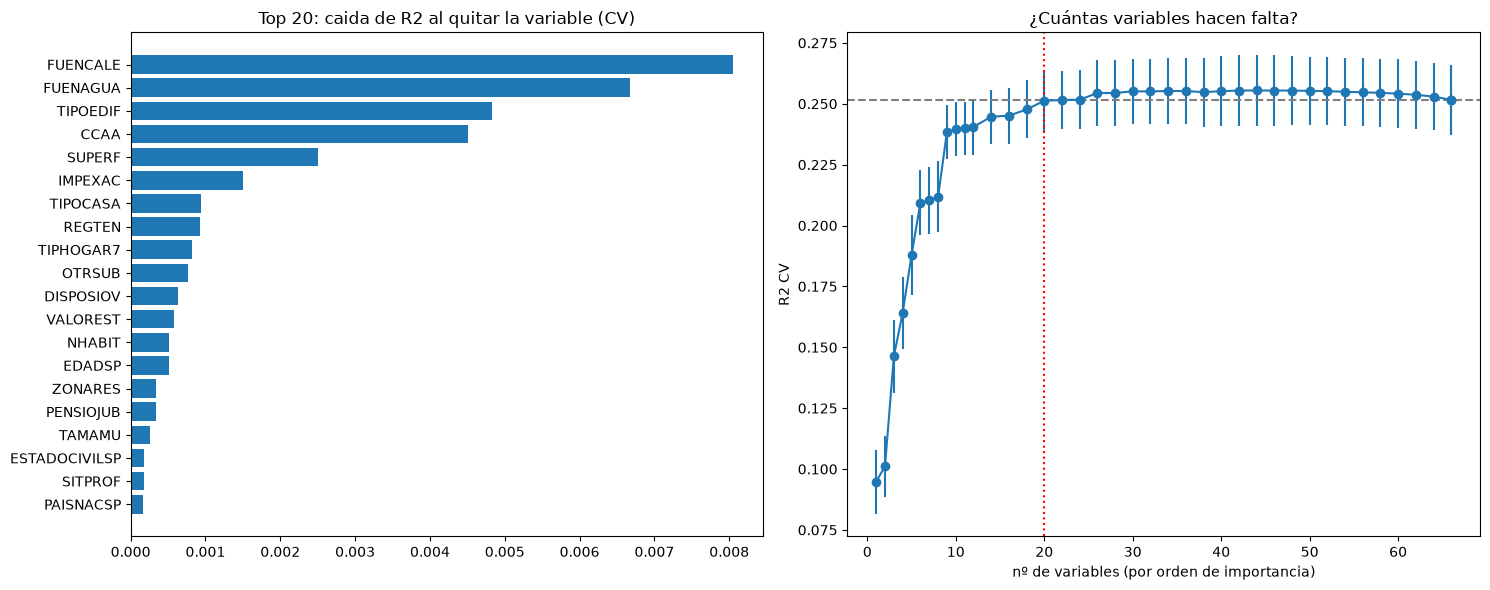

,perm,quitar_una,rank_perm,rank_quitar
FUENCALE,0.0508,0.0081,3.0,1.0
FUENAGUA,0.0451,0.0067,4.0,2.0
TIPOEDIF,0.0192,0.0048,8.0,3.0
CCAA,0.0158,0.0045,9.0,4.0
SUPERF,0.0123,0.0025,11.0,5.0
IMPEXAC,0.0090,0.0015,14.0,6.0
TIPOCASA,0.0027,0.0009,26.0,7.0
REGTEN,0.0032,0.0009,22.0,8.0
TIPHOGAR7,0.0112,0.0008,12.0,9.0
OTRSUB,0.0021,0.0008,31.0,10.0


In [24]:
# ============================================================
# Importancia por variable ORIGINAL y justificacion del corte
# Pegar en el notebook 03, despues de definir tus listas de columnas y pipelines
# (no_aplica_cols, no_consta_cols, moda_cat_cols, cat_multiclase_cols, num_con_nulos, num_sin_nulos,
#  no_aplica_pipe, no_consta_pipe, moda_cat_pipe, cat_multiclase_pipe, num_nulos_pipe, num_limpias_pipe,
#  X_train, y_train). Usa solo train: el test no se toca.
# ============================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_validate
from sklearn.inspection import permutation_importance
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

def pipeline_con(variables, modelo=None):
    """Mismo pipeline que ya tienes, pero usando solo las 'variables' indicadas."""
    v = set(variables)
    bloques = [
        ("cat_no_aplica", no_aplica_pipe,       [c for c in no_aplica_cols if c in v]),
        ("cat_no_consta", no_consta_pipe,       [c for c in no_consta_cols if c in v]),
        ("cat_moda",      moda_cat_pipe,        [c for c in moda_cat_cols if c in v]),
        ("cat_multi",     cat_multiclase_pipe,  [c for c in cat_multiclase_cols if c in v]),
        ("num_nulos",     num_nulos_pipe,       [c for c in num_con_nulos if c in v]),
        ("num_limpias",   num_limpias_pipe,     [c for c in num_sin_nulos if c in v]),
    ]
    bloques = [b for b in bloques if len(b[2]) > 0]           # quita bloques vacios
    return Pipeline([("prep", ColumnTransformer(bloques, remainder="drop")),
                     ("reg", modelo if modelo is not None else Ridge(alpha=1.0))])

def r2_cv(variables, cv=5):
    return cross_validate(pipeline_con(variables), X_train, y_train, cv=cv, scoring="r2", n_jobs=-1)["test_score"]

TODAS = sorted(set(no_aplica_cols + no_consta_cols + moda_cat_cols + cat_multiclase_cols + num_con_nulos + num_sin_nulos))

# ---- MÉTODO 1: importancia por permutacion (rapido) ----
# Entrena en cada fold, y en el fold de validacion baraja UNA variable original cada vez:
# cuanto cae el R2 = cuanto dependia el modelo de ella. Va directamente por variable original (no por columna OHE).
def importancia_permutacion(variables, n_repeats=5, seed=0):
    folds = []
    for tr, va in KFold(5, shuffle=True, random_state=seed).split(X_train):
        m = pipeline_con(variables).fit(X_train.iloc[tr], y_train.iloc[tr])
        r = permutation_importance(m, X_train.iloc[va][variables], y_train.iloc[va],
                                   scoring="r2", n_repeats=n_repeats, random_state=seed, n_jobs=-1)
        folds.append(r.importances_mean)
    folds = np.array(folds)
    return pd.DataFrame({"caida_r2": folds.mean(0), "std_folds": folds.std(0)}, index=variables)

# ---- MÉTODO 2: quitar una variable (mas lento, mas "honesto") ----
# R2 con todas - R2 sin esa variable (CV completo cada vez). Con ~55 variables son ~1-2 min.
def importancia_quitar_una(variables):
    base = r2_cv(variables).mean()
    return pd.Series({v: base - r2_cv([c for c in variables if c != v]).mean() for v in variables}, name="caida_r2")

# ---- CURVA: cuantas variables hacen falta? ----
def curva_top_k(orden, ks):
    filas = []
    for k in ks:
        s = r2_cv(orden[:k]); filas.append({"k": k, "r2": s.mean(), "std": s.std()})
    return pd.DataFrame(filas)

if __name__ == "__main__" or True:
    imp_perm = importancia_permutacion(TODAS).sort_values("caida_r2", ascending=False)
    imp_quit = importancia_quitar_una(TODAS).sort_values(ascending=False)
    comparacion = pd.DataFrame({"perm": imp_perm["caida_r2"], "quitar_una": imp_quit})
    comparacion["rank_perm"] = comparacion.perm.rank(ascending=False)
    comparacion["rank_quitar"] = comparacion.quitar_una.rank(ascending=False)
    orden = imp_quit.index.tolist()                      # orden final: "quitar una" (la permutacion sirve de contraste)
    curva = curva_top_k(orden, list(range(1, 13)) + list(range(14, len(orden) + 1, 2)) + [len(orden)])
    r2_full = curva.r2.iloc[-1]
    k_min = int(curva[curva.r2 >= r2_full - 0.002].k.min())   # minimo k que no pierde R2 (tolerancia 0.002)
    print("Orden por importancia:", orden)
    print(f"R2 completo={r2_full:.4f} | k minimo sin perder R2 (tol 0.002): {k_min}")
    print("Seleccion:", orden[:k_min])

    fig, ax = plt.subplots(1, 2, figsize=(15, 6))
    top = imp_quit.head(20)[::-1]
    ax[0].barh(top.index, top.values); ax[0].set_title("Top 20: caida de R2 al quitar la variable (CV)")
    ax[1].errorbar(curva.k, curva.r2, yerr=curva["std"], marker="o"); ax[1].axhline(r2_full, ls="--", c="gray")
    ax[1].axvline(k_min, ls=":", c="red"); ax[1].set_xlabel("nº de variables (por orden de importancia)"); ax[1].set_ylabel("R2 CV")
    ax[1].set_title("¿Cuántas variables hacen falta?"); plt.tight_layout(); plt.show()
    display(comparacion.sort_values("rank_quitar").round(4).head(25))

In [25]:
# 1. Lista base de las 22 variables
cols_22_base = [
    "CCAA",
    "FUENCALE",
    "FUENAGUA",
    "TIPOEDIF",
    "SUPERF",
    "TIPHOGAR1",
    "IMPEXAC",
    "TIPOCASA",
    "OTRSUB",
    "REGTEN",
    "VALOREST",
    "DISPOSIOV",
    "NHABIT",
    "ZONARES",
    "EDADSP",
    "PENSIOJUB",
    "TAMAMU",
    "ESTADOCIVILSP",
    "ESTUDREDSP",
    "SITPROF",
    "PAISNACSP",
    "DENSIDAD",
]

# 2. Candidatas a versión reducida conocidas del proyecto (se usan si existen en X_train)
# Si alguna de las 22 tiene otra columna reducida en tu CSV, añádela aquí: {"ORIGINAL": "REDUCIDA"}
mapeo_reducidas = {
    "ESTUDREDSP": "ESTUDREDSP",
    "SITPROF": "SITUREDSP",
}

cols_22_final = []
sustituciones = {}
for col in cols_22_base:
  red = mapeo_reducidas.get(col)
  if red and red in X_train.columns and red != col:
    cols_22_final.append(red)
    sustituciones[col] = red
  elif col in X_train.columns:
    cols_22_final.append(col)

# Evitar duplicados conservando el orden
cols_22_final = list(dict.fromkeys(cols_22_final))

print(f"Total variables en el modelo ({len(cols_22_final)}):", cols_22_final)
print("Sustituciones aplicadas:", sustituciones if sustituciones else "Ninguna")


# 3. Pipeline filtrando a las variables seleccionadas y quitando bloques vacíos
def construir_pipe_subset(variables, alpha=1.0):
  v = set(variables)
  bloques = [
      ("cat_no_aplica", no_aplica_pipe, [c for c in no_aplica_cols if c in v]),
      ("cat_no_consta", no_consta_pipe, [c for c in no_consta_cols if c in v]),
      ("cat_moda", moda_cat_pipe, [c for c in moda_cat_cols if c in v]),
      (
          "cat_multiclase",
          cat_multiclase_pipe,
          [c for c in cat_multiclase_cols if c in v],
      ),
      ("num_nulos", num_nulos_pipe, [c for c in num_con_nulos if c in v]),
      ("num_limpias", num_limpias_pipe, [c for c in num_sin_nulos if c in v]),
  ]
  bloques = [
      (nombre, trans, cols) for nombre, trans, cols in bloques if len(cols) > 0
  ]
  return Pipeline([
      ("prep", ColumnTransformer(transformers=bloques, remainder="drop")),
      ("reg", Ridge(alpha=alpha)),
  ])


# 4. Cross-validation (usa el mismo cv que en tu comparativa; aquí KFold 5 barajado)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
}

todas_cols = list(
    dict.fromkeys(
        no_aplica_cols
        + no_consta_cols
        + moda_cat_cols
        + cat_multiclase_cols
        + num_con_nulos
        + num_sin_nulos
    )
)
todas_cols = [c for c in todas_cols if c in X_train.columns]

pipe_full = construir_pipe_subset(todas_cols, alpha=1.0)
pipe_22 = construir_pipe_subset(cols_22_final, alpha=1.0)

res_full = cross_validate(
    pipe_full, X_train, y_train, cv=kf, scoring=scoring, n_jobs=-1
)
res_22 = cross_validate(
    pipe_22, X_train, y_train, cv=kf, scoring=scoring, n_jobs=-1
)

df_comp_22 = pd.DataFrame(
    [
        {
            "modelo": f"Full ({len(todas_cols)} vars)",
            "r2_mean": res_full["test_r2"].mean(),
            "r2_std": res_full["test_r2"].std(),
            "rmse": -res_full["test_rmse"].mean(),
            "mae": -res_full["test_mae"].mean(),
        },
        {
            "modelo": f"Subconjunto ({len(cols_22_final)} vars)",
            "r2_mean": res_22["test_r2"].mean(),
            "r2_std": res_22["test_r2"].std(),
            "rmse": -res_22["test_rmse"].mean(),
            "mae": -res_22["test_mae"].mean(),
        },
    ]
).set_index("modelo")

df_comp_22["delta_r2"] = df_comp_22["r2_mean"] - df_comp_22.iloc[0]["r2_mean"]
df_comp_22["delta_rmse"] = df_comp_22["rmse"] - df_comp_22.iloc[0]["rmse"]
df_comp_22["delta_mae"] = df_comp_22["mae"] - df_comp_22.iloc[0]["mae"]

df_comp_22.round(4)

Total variables en el modelo (22): ['CCAA', 'FUENCALE', 'FUENAGUA', 'TIPOEDIF', 'SUPERF', 'TIPHOGAR1', 'IMPEXAC', 'TIPOCASA', 'OTRSUB', 'REGTEN', 'VALOREST', 'DISPOSIOV', 'NHABIT', 'ZONARES', 'EDADSP', 'PENSIOJUB', 'TAMAMU', 'ESTADOCIVILSP', 'ESTUDREDSP', 'SITUREDSP', 'PAISNACSP', 'DENSIDAD']
Sustituciones aplicadas: {'SITPROF': 'SITUREDSP'}


,r2_mean,r2_std,rmse,mae,delta_r2,delta_rmse,delta_mae
modelo,,,,,,,
Full (66 vars),0.2464,0.0120,679.6706,486.8097,0.0,0.0000,0.0000
Subconjunto (22 vars),0.2464,0.0082,679.7179,486.4733,0.0,0.0472,-0.3363


In [27]:
to_dense = FunctionTransformer(
    lambda x: x.toarray() if hasattr(x, "toarray") else x
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
}

hgb_pipe = Pipeline([
    ("prep", preprocessor),
    ("to_dense", to_dense),
    ("model", HistGradientBoostingRegressor(random_state=42)),
])

scores_hgb = cross_validate(
    hgb_pipe,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
)

print(f"R2 medio:   {scores_hgb['test_r2'].mean():.4f} (+/- {scores_hgb['test_r2'].std():.4f})")
print(f"RMSE medio: {-scores_hgb['test_rmse'].mean():.2f} (+/- {scores_hgb['test_rmse'].std():.2f})")
print(f"MAE medio:  {-scores_hgb['test_mae'].mean():.2f} (+/- {scores_hgb['test_mae'].std():.2f})")

R2 medio:   0.2608 (+/- 0.0123)
RMSE medio: 673.14 (+/- 16.82)
MAE medio:  479.95 (+/- 8.78)


In [11]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
}

rf_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_features="sqrt",
        n_jobs=1,
        random_state=42,
    )),
])

scores_rf = cross_validate(
    rf_pipe,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
)

print(f"R2 medio (CV 5-fold):   {scores_rf['test_r2'].mean():.4f} (+/- {scores_rf['test_r2'].std():.4f})")
print(f"RMSE medio (CV 5-fold): {-scores_rf['test_rmse'].mean():.2f} (+/- {scores_rf['test_rmse'].std():.2f})")
print(f"MAE medio (CV 5-fold):  {-scores_rf['test_mae'].mean():.2f} (+/- {scores_rf['test_mae'].std():.2f})")

R2 medio (CV 5-fold):   0.2448 (+/- 0.0068)
RMSE medio (CV 5-fold): 680.49 (+/- 18.59)
MAE medio (CV 5-fold):  488.86 (+/- 10.11)


In [14]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
}

enet_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", ElasticNet(
        alpha=0.1,
        l1_ratio=0.3,
        max_iter=5000,
        random_state=42,
    )),
])

scores_enet = cross_validate(
    enet_pipe,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
)

print(f"R2 medio (CV 5-fold):   {scores_enet['test_r2'].mean():.4f} (+/- {scores_enet['test_r2'].std():.4f})")
print(f"RMSE medio (CV 5-fold): {-scores_enet['test_rmse'].mean():.2f} (+/- {scores_enet['test_rmse'].std():.2f})")
print(f"MAE medio (CV 5-fold):  {-scores_enet['test_mae'].mean():.2f} (+/- {scores_enet['test_mae'].std():.2f})")

R2 medio (CV 5-fold):   0.2458 (+/- 0.0085)
RMSE medio (CV 5-fold): 680.00 (+/- 17.96)
MAE medio (CV 5-fold):  486.24 (+/- 8.60)


In [16]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
}

mlp_pipe = Pipeline([
    ("prep", preprocessor),
    ("scaler", MaxAbsScaler()),
    ("model", MLPRegressor(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        alpha=1.0,
        early_stopping=True,
        validation_fraction=0.1,
        max_iter=300,
        random_state=42,
    )),
])

scores_mlp = cross_validate(
    mlp_pipe,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
)

print(f"R2 medio (CV 5-fold):   {scores_mlp['test_r2'].mean():.4f} (+/- {scores_mlp['test_r2'].std():.4f})")
print(f"RMSE medio (CV 5-fold): {-scores_mlp['test_rmse'].mean():.2f} (+/- {scores_mlp['test_rmse'].std():.2f})")
print(f"MAE medio (CV 5-fold):  {-scores_mlp['test_mae'].mean():.2f} (+/- {scores_mlp['test_mae'].std():.2f})")

R2 medio (CV 5-fold):   0.2528 (+/- 0.0092)
RMSE medio (CV 5-fold): 676.86 (+/- 17.86)
MAE medio (CV 5-fold):  484.14 (+/- 9.49)


In [12]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
}

mlp_pipe = Pipeline([
    ("prep", preprocessor),
    ("scaler", MaxAbsScaler()),
    ("model", MLPRegressor(
        activation="relu",
        early_stopping=True,
        validation_fraction=0.1,
        max_iter=300,
        random_state=42,
    )),
])

param_grid_mlp = {
    "model__hidden_layer_sizes": [(128, 64), (128,), (256, 128)],
    "model__alpha": [0.1, 1.0, 10.0],
    "model__learning_rate_init": [0.0005, 0.001],
}

grid_mlp = GridSearchCV(
    estimator=mlp_pipe,
    param_grid=param_grid_mlp,
    cv=cv,
    scoring=scoring,
    refit="r2",
    n_jobs=-1,
    verbose=1,
)

grid_mlp.fit(X_train, y_train)

best_idx_mlp = grid_mlp.best_index_
print("Mejores parámetros MLP:", grid_mlp.best_params_)
print(f"Mejor R2 (CV 5-fold):   {grid_mlp.cv_results_['mean_test_r2'][best_idx_mlp]:.4f}")
print(f"RMSE asociado:          {-grid_mlp.cv_results_['mean_test_rmse'][best_idx_mlp]:.2f}")
print(f"MAE asociado:           {-grid_mlp.cv_results_['mean_test_mae'][best_idx_mlp]:.2f}")

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Mejores parámetros MLP: {'model__alpha': 0.1, 'model__hidden_layer_sizes': (256, 128), 'model__learning_rate_init': 0.0005}
Mejor R2 (CV 5-fold):   0.2566
RMSE asociado:          675.08
MAE asociado:           482.65


In [14]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
}

to_dense = FunctionTransformer(
    lambda x: x.toarray() if hasattr(x, "toarray") else x
)

hgb_pipe = Pipeline([
    ("prep", preprocessor),
    ("to_dense", to_dense),
    ("model", HistGradientBoostingRegressor(
        max_iter=300,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=42,
    )),
])

param_grid_hgb = {
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0.0, 1.0, 10.0],
}

grid_hgb = GridSearchCV(
    estimator=hgb_pipe,
    param_grid=param_grid_hgb,
    cv=cv,
    scoring=scoring,
    refit="r2",
    n_jobs=-1,
    verbose=1,
)

grid_hgb.fit(X_train, y_train)

idx = grid_hgb.best_index_
print("Mejores parámetros HGB:", grid_hgb.best_params_)
print(f"Mejor R2 (CV 5-fold):   {grid_hgb.cv_results_['mean_test_r2'][idx]:.4f}")
print(f"RMSE asociado:          {-grid_hgb.cv_results_['mean_test_rmse'][idx]:.2f}")
print(f"MAE asociado:           {-grid_hgb.cv_results_['mean_test_mae'][idx]:.2f}")

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Mejores parámetros HGB: {'model__l2_regularization': 1.0, 'model__learning_rate': 0.05, 'model__max_leaf_nodes': 15, 'model__min_samples_leaf': 100}
Mejor R2 (CV 5-fold):   0.2692
RMSE asociado:          669.39
MAE asociado:           478.02


In [19]:
from sklearn.inspection import permutation_importance

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
}
to_dense = FunctionTransformer(
    lambda x: x.toarray() if hasattr(x, "toarray") else x
)


def build_hgb_pipeline(cols, num_cols_all, cat_cols_all):
    num_cols = [c for c in cols if c in num_cols_all]
    cat_cols = [c for c in cols if c in cat_cols_all]

    transformers = []
    if num_cols:
        num_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ])
        transformers.append(("num", num_pipe, num_cols))

    if cat_cols:
        cat_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(
                handle_unknown="infrequent_if_exist",
                sparse_output=True,
            )),
        ])
        transformers.append(("cat", cat_pipe, cat_cols))

    prep = ColumnTransformer(transformers=transformers, remainder="drop")

    model = HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=100,
        l2_regularization=1.0,
        max_iter=300,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=42,
    )

    return Pipeline([
        ("prep", prep),
        ("to_dense", to_dense),
        ("model", model),
    ])


num_cols_all = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols_all = [c for c in X_train.columns if c not in num_cols_all]

# 1. Ajustar pipeline base y calcular importancia por permutación (orden: menor -> mayor)
base_pipe = build_hgb_pipeline(X_train.columns.tolist(), num_cols_all, cat_cols_all)
base_pipe.fit(X_train, y_train)

perm = permutation_importance(
    base_pipe,
    X_train,
    y_train,
    scoring="r2",
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
)

order_idx = np.argsort(perm.importances_mean)
low_to_high_impact_cols = X_train.columns[order_idx].tolist()

print("5 variables con menor impacto:", low_to_high_impact_cols[:5])
print("5 variables con mayor impacto:", low_to_high_impact_cols[-5:])

# 2. Probar retirada progresiva en CV 5-fold
drop_counts = [0, 5, 10, 15, 20]
results = []

for k_drop in drop_counts:
    kept_cols = [c for c in X_train.columns if c not in low_to_high_impact_cols[:k_drop]]
    pipe = build_hgb_pipeline(kept_cols, num_cols_all, cat_cols_all)

    scores = cross_validate(
        pipe,
        X_train[kept_cols],
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
    )

    results.append({
        "quitadas": k_drop,
        "vars_restantes": len(kept_cols),
        "r2_mean": scores["test_r2"].mean(),
        "rmse_mean": (-scores["test_rmse"]).mean(),
        "mae_mean": (-scores["test_mae"]).mean(),
    })

df_drop = pd.DataFrame(results)
print(df_drop.to_string(index=False))

5 variables con menor impacto: ['JORNADASP', 'OCUSP', 'SITUREDSP', 'CONTRATO', 'SITURESSP']
5 variables con mayor impacto: ['FUENCALE', 'TIPOEDIF', 'IMPEXAC', 'FUENAGUA', 'SUPERF']
 quitadas  vars_restantes  r2_mean  rmse_mean   mae_mean
        0              86 0.268012 669.891639 478.433931
        5              81 0.268042 669.878180 478.309189
       10              76 0.268478 669.683215 478.363167
       15              71 0.268559 669.653285 478.357639
       20              66 0.267944 669.921278 478.404069


In [20]:
top_15_lowest = low_to_high_impact_cols[:15]
print("15 variables de menor impacto:")
for i, col in enumerate(top_15_lowest, start=1):
    print(f"{i:2d}. {col}")

# 2. Tabla completa con todas las variables (por ejemplo, las 30 de menor impacto o todas las 86)
df_importances = pd.DataFrame({
    "variable": X_train.columns,
    "r2_drop_mean": perm.importances_mean,
    "r2_drop_std": perm.importances_std,
}).sort_values("r2_drop_mean", ascending=True).reset_index(drop=True)

# Ver las 30 de menor impacto:
print("\n30 variables de menor impacto:")
print(df_importances.head(30).to_string(index=False))

15 variables de menor impacto:
 1. JORNADASP
 2. OCUSP
 3. SITUREDSP
 4. CONTRATO
 5. SITURESSP
 6. AGUACALI
 7. PENSIOINCAP
 8. UC2
 9. PENSIOTR
10. RENTAS
11. NUMESTU
12. NMIEM7
13. TRABAJO
14. SITUACTSP
15. FUENPRIN

30 variables de menor impacto:
   variable  r2_drop_mean  r2_drop_std
  JORNADASP      0.000000     0.000000
      OCUSP      0.000000     0.000000
  SITUREDSP      0.000000     0.000000
   CONTRATO      0.000000     0.000000
  SITURESSP      0.000000     0.000000
   AGUACALI      0.000000     0.000000
PENSIOINCAP      0.000000     0.000000
        UC2      0.000001     0.000020
   PENSIOTR      0.000018     0.000009
     RENTAS      0.000029     0.000007
    NUMESTU      0.000032     0.000012
     NMIEM7      0.000053     0.000013
    TRABAJO      0.000060     0.000025
  SITUACTSP      0.000063     0.000041
   FUENPRIN      0.000093     0.000028
PAISMADRESP      0.000094     0.000008
     NMIEM3      0.000102     0.000037
   TIPOCONT      0.000109     0.000015
    NNIN

In [16]:
to_dense = FunctionTransformer(
    lambda x: x.toarray() if hasattr(x, "toarray") else x
)

best_model = Pipeline([
    ("prep", preprocessor),
    ("to_dense", to_dense),
    ("model", HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=100,
        l2_regularization=1.0,
        max_iter=300,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=42,
    )),
])

best_model.fit(X_train, y_train)
y_pred_test = best_model.predict(X_test)

r2_test = r2_score(y_test, y_pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
mae_test = mean_absolute_error(y_test, y_pred_test)

print(f"Test R2:   {r2_test:.4f}  (CV 5-fold: 0.2692)")
print(f"Test RMSE: {rmse_test:.2f}   (CV 5-fold: 669.39)")
print(f"Test MAE:  {mae_test:.2f}   (CV 5-fold: 478.02)")

Test R2:   0.2723  (CV 5-fold: 0.2692)
Test RMSE: 714.07   (CV 5-fold: 669.39)
Test MAE:  486.58   (CV 5-fold: 478.02)
